# 03 — No supervisado: aprender la forma del tráfico benigno

Los modelos del notebook 02 necesitan etiquetas y, cuando cambia el escenario, se caen. Acá probamos lo contrario: mirar solo tráfico benigno, aprender qué forma tiene y marcar como raro todo lo que se aleje. Si el detector nunca vio un ataque, no puede reconocer la firma de un ataque: lo único que puede decir es "esto no se parece a lo normal".

**Recorrido:**

1. Decidir qué columnas entran y por qué.
2. Entrenar con benigno y calibrar el umbral.
3. Elegir el número de grupos con evidencia, no a ojo.
4. Interpretar qué representan esos grupos.
5. Comparar K-Means, BIRCH y DBSCAN sobre los ocho escenarios.
6. Ver el protocolo online y su límite.
7. Cargar el modelo guardado y puntuar un escenario como en producción.

## Antes de empezar: si lo abrís en Google Colab

Este notebook vive en el repo y lee `datasets/`, `src/`, `resultados/` y `modelos/` desde la raíz del proyecto. En Colab esos archivos no existen, así que la celda de abajo clona el repo en `/content/data4cyber` y se para ahí.

**Cómo abrirlo:**

1. En Colab: *Archivo → Abrir notebook → GitHub*, pegá la URL del repo y elegí el notebook.
2. Ejecutá la primera celda. Clona el repo (una sola vez por sesión) y queda listo para correr.

Fuera de Colab la celda no hace nada.


In [1]:
# --- Preparar el entorno: solo hace algo si estás en Google Colab ---
import os
import subprocess
from pathlib import Path

REPO = "https://github.com/maxiricalde/data4cyber.git"
DESTINO = Path("/content/data4cyber")

try:
    import google.colab  # noqa: F401

    EN_COLAB = True
except ImportError:
    EN_COLAB = False

if EN_COLAB:
    # Una sola vez por sesión: clonar el repo y pararse en su raíz.
    if not (DESTINO / "src" / "data.py").exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO, str(DESTINO)], check=True)
    os.chdir(DESTINO)
    print("proyecto en:", os.getcwd())
else:
    print("corriendo local: no hay nada que preparar")


corriendo local: no hay nada que preparar


In [2]:
import os
import subprocess
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.cluster import Birch, DBSCAN, KMeans
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.metrics import roc_auc_score, silhouette_score
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# El notebook vive en notebooks/, pero los datasets y src/ están en la raíz del proyecto.
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "data.py").exists())
os.chdir(RAIZ)
sys.path.insert(0, str(RAIZ))

from src.data import build_matrices
from src.features import detrend

pd.set_option("display.width", 140)
print("raíz del proyecto:", RAIZ)

raíz del proyecto: /media/windows/Users/pablo/Documents/UNSA/4to/MetodosCuantitativos/TPFinal


## 0. Qué le damos de entrada

Una decisión antes de cualquier modelo: ¿entran las mediciones tal como vienen, o su variación dentro de una ventana?

En el notebook 02 quedó medido que los **niveles absolutos** dejan reconstruir el reloj del escenario: un clasificador entrenado solo con la posición de la fila llega a AUC 0,961. Ese atajo no es detección. Si le damos niveles a un detector no supervisado, va a aprender "a esta hora los valores son así", que es exactamente el atajo que queremos evitar.

Por eso usamos la **dinámica local**: a cada columna le restamos su mínimo móvil de 120 s. El resultado mide cuánto se movió la señal en los últimos dos minutos, y queda comparable entre escenarios porque ya no depende del nivel de operación.

In [3]:
ESCENARIOS = ("S0", "S1", "S1alt", "S2", "S3", "S4", "S5", "S6")

frames = pd.concat(
    [pd.read_csv(f"datasets/dataset{nombre}.csv").assign(scenario=nombre) for nombre in ESCENARIOS],
    ignore_index=True,
)

m = build_matrices(frames)
X_niveles = m.X
X = detrend(X_niveles, m.scenario, method="range", window=120)
y = m.y_binary
escenario = m.scenario
posicion = m.position

print("filas:", len(X), "| columnas de entrada:", X.shape[1])
print("ataques:", int(y.sum()), f"({100 * y.mean():.1f} %)")
print("filas benignas:", int((y == 0).sum()))

filas: 14354 | columnas de entrada: 139
ataques: 7586 (52.8 %)
filas benignas: 6768


Sobre 139 columnas de dinámica. El notebook 02 mostró que se pueden reducir a 15 sin perder el punto operativo; acá arrancamos con las 139 para que el detector no dependa de una receta elegida mirando las etiquetas, y al final comparamos las dos versiones.

Un detalle que aparece más abajo: la proyección PCA retiene **15 componentes** para el 95 % de la varianza. Las 139 columnas de dinámica no aportan 139 dimensiones de información; aportan alrededor de 15.

## 1. Entrenar solo con benigno: el protocolo

El detector nunca ve una fila de ataque. Para cada escenario que reservamos, el entrenamiento usa **las filas benignas de los otros siete**, y el umbral se calibra sobre el 20 % final del benigno de entrenamiento (una porción cronológica, como si fuera el último tramo de operación conocido).

Todo el preprocesamiento —imputar, escalar, proyectar con PCA— se ajusta **dentro** de ese conjunto. Si lo ajustáramos con todos los datos, el escenario reservado influiría en la escala y en la proyección: eso es fuga de información.

Trabajamos el fold que reserva `S1`.

In [4]:
RESERVADO = "S1"
FRACCION_VALIDACION = 0.20
CUANTIL = 95
SEMILLA = 42

prueba = (escenario == RESERVADO).to_numpy()
benigno = (y == 0).to_numpy()
entrenamiento = (~prueba) & benigno

# El último 20 % del benigno de cada escenario de entrenamiento calibra el umbral.
validacion = np.zeros(len(X), dtype=bool)
for nombre in ESCENARIOS:
    filas = np.where(entrenamiento & (escenario == nombre).to_numpy())[0]
    if len(filas):
        validacion[filas[int(len(filas) * (1 - FRACCION_VALIDACION)):]] = True
ajuste = entrenamiento & ~validacion

preproceso = Pipeline([
    ("imputar", SimpleImputer(strategy="median")),
    ("escalar", StandardScaler()),
    ("pca", PCA(n_components=0.95, random_state=SEMILLA)),
])
Z_ajuste = preproceso.fit_transform(X.loc[ajuste])
Z_validacion = preproceso.transform(X.loc[validacion])
Z_prueba = preproceso.transform(X.loc[prueba])

print(f"filas de ajuste:     {ajuste.sum():,}")
print(f"filas de validación: {validacion.sum():,}")
print(f"filas de prueba:     {prueba.sum():,} ({int(y[prueba].sum())} ataques)")
print(f"componentes PCA:     {Z_ajuste.shape[1]} (95 % de la varianza)")

filas de ajuste:     4,704
filas de validación: 1,179
filas de prueba:     1,798 (913 ataques)
componentes PCA:     15 (95 % de la varianza)


Guardamos también las filas de ajuste sin proyectar, porque para interpretar los grupos necesitamos volver a las columnas originales.

In [5]:
X_ajuste = X.loc[ajuste]
escenario_ajuste = escenario[ajuste]

print(X_ajuste.shape)

(4704, 139)


## 2. ¿Cuántos grupos?

"Grupo" acá significa **régimen de operación**: por ejemplo, con y sin generación fotovoltaica, o con carga alta y baja. El número no se elige por conveniencia: se mide.

Dos criterios que suelen ir juntos:

- **Inercia** (suma de distancias al cuadrado dentro de cada grupo): siempre baja al agregar grupos, así que sirve para ver dónde deja de mejorar rápido — el "codo".
- **Silueta**: qué tan bien separado está cada punto de su grupo respecto del más cercano. Va de -1 a 1 y no depende del número de grupos, así que permite comparar.

Se prueban k = 2 a 10 y se elige el que maximiza la silueta.

In [6]:
filas = []
for k in range(2, 11):
    modelo = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA).fit(Z_ajuste)
    silueta = silhouette_score(Z_ajuste, modelo.labels_, sample_size=2000, random_state=SEMILLA)
    filas.append({"k": k, "inercia": modelo.inertia_, "silueta": silueta})

barrido_k = pd.DataFrame(filas).round(3)
print(barrido_k.to_string(index=False))

 k    inercia  silueta
 2 456264.642    0.306
 3 353997.987    0.333
 4 286183.893    0.340
 5 225237.736    0.336
 6 200803.224    0.364
 7 185111.888    0.360
 8 168786.912    0.371
 9 158102.744    0.306
10 148385.793    0.288


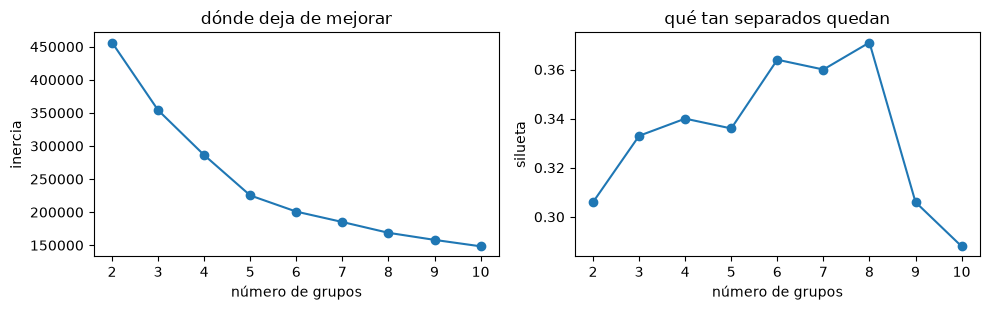

In [7]:
fig, (izq, der) = plt.subplots(1, 2, figsize=(10, 3.2))

izq.plot(barrido_k["k"], barrido_k["inercia"], marker="o")
izq.set_xlabel("número de grupos")
izq.set_ylabel("inercia")
izq.set_title("dónde deja de mejorar")

der.plot(barrido_k["k"], barrido_k["silueta"], marker="o")
der.set_xlabel("número de grupos")
der.set_ylabel("silueta")
der.set_title("qué tan separados quedan")

plt.tight_layout()
plt.show()

Se leen dos cosas. La inercia baja de 456 mil a 201 mil entre k=2 y k=6 —unos 28 mil por grupo— y después apenas 16 mil, 11 mil y 10 mil: el codo está en 5 o 6. La silueta sube despacio hasta **k = 8** (0,371) y se derrumba en k = 9 (0,306), pero en todos los casos queda entre 0,29 y 0,37.

Ese valor es el que importa: una silueta de 0,37 dice que los regímenes existen pero **se solapan en el borde**. Ningún punto está muy lejos de otro grupo, y eso anticipa el resultado: el detector va a ordenar las filas razonablemente y va a sufrir para elegir el umbral.

Nos quedamos con el k que maximiza la silueta, el mismo criterio que usa `src/unsupervised.py`.

In [8]:
K_ELEGIDO = int(barrido_k.loc[barrido_k["silueta"].idxmax(), "k"])
print("k elegido por silueta:", K_ELEGIDO)

k elegido por silueta: 8


**BIRCH y DBSCAN no reciben un k: reciben una escala.** El "número de grupos" sale del parámetro, y para elegirlo se compara la silueta **entre valores del mismo modelo** —nunca contra el k de K-Means.

La razón: la silueta sube cuando los grupos son chicos y numerosos, porque cada punto queda cerca de su centro. BIRCH con umbral 0,2 produce 944 subgrupos minúsculos y por eso su silueta da 0,71; no es mejor que la de K-Means con 8 grupos, es otra escala de análisis.

- **BIRCH** agrupa con un umbral de radio: más chico, más subgrupos. Se prueban 0,2 / 0,5 / 1,0.
- **DBSCAN** agrupa por densidad con `eps`, y `eps` sale de la curva de distancias al quinto vecino: se toma el percentil 90 de esa distancia. Es el método estándar, no un valor a ojo.

In [9]:
filas = []
for umbral in (0.2, 0.5, 1.0):
    modelo = Birch(threshold=umbral, branching_factor=50, n_clusters=None).fit(Z_ajuste)
    etiquetas = modelo.labels_
    silueta = float("nan")
    if len(np.unique(etiquetas)) > 1:
        silueta = silhouette_score(Z_ajuste, etiquetas, sample_size=2000, random_state=SEMILLA)
    filas.append({
        "umbral": umbral,
        "subgrupos": len(modelo.subcluster_centers_),
        "grupos": len(np.unique(etiquetas)),
        "silueta": silueta,
    })

print("BIRCH")
print(pd.DataFrame(filas).round(3).to_string(index=False))

vecinos = NearestNeighbors(n_neighbors=5).fit(Z_ajuste)
distancias, _ = vecinos.kneighbors(Z_ajuste)
EPS = max(float(np.percentile(distancias[:, -1], 90)), 1e-6)

barrido_birch = pd.DataFrame(filas)
MEJOR_UMBRAL = float(barrido_birch.loc[barrido_birch["silueta"].idxmax(), "umbral"])
print(f"\numbral de BIRCH elegido: {MEJOR_UMBRAL}")
print(f"DBSCAN: eps = {EPS:.3f} (percentil 90 de la distancia al quinto vecino)")

BIRCH
 umbral  subgrupos  grupos  silueta
    0.2        944     944    0.713
    0.5        567     566    0.696
    1.0        331     331    0.651

umbral de BIRCH elegido: 0.2
DBSCAN: eps = 1.169 (percentil 90 de la distancia al quinto vecino)


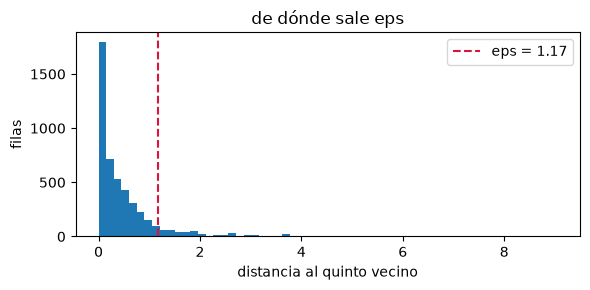

In [10]:
fig, eje = plt.subplots(figsize=(6, 3))
eje.hist(distancias[:, -1], bins=60)
eje.axvline(EPS, color="crimson", linestyle="--", label=f"eps = {EPS:.2f}")
eje.set_xlabel("distancia al quinto vecino")
eje.set_ylabel("filas")
eje.set_title("de dónde sale eps")
eje.legend()
plt.tight_layout()
plt.show()

## 3. Los tres modelos, un fold completo

Los tres hacen lo mismo con distinta forma, y eso es justamente lo que hay que comparar:

| Modelo | Qué asume | Cómo puntúa una fila nueva |
|---|---|---|
| K-Means | los regímenes son esféricos y de tamaño parecido | distancia al centro más cercano |
| BIRCH | los regímenes caben en subgrupos de radio acotado | distancia al subgrupo más cercano |
| DBSCAN | los regímenes son zonas densas separadas por vacío | distancia al punto denso más cercano |

La lógica común: entrenamos solo con benigno, el puntaje es la distancia a lo conocido, y el umbral es el percentil 95 de esa distancia en la validación benigna. Un 5 % de falsas alarmas en el conjunto de calibración.

In [11]:
def puntaje(modelo, nombre, Z):
    if nombre == "kmeans":
        return modelo.transform(Z).min(axis=1)
    if nombre == "birch":
        vecino = NearestNeighbors(n_neighbors=1).fit(modelo.subcluster_centers_)
        return vecino.kneighbors(Z)[0][:, 0]
    nucleo = modelo.components_
    return NearestNeighbors(n_neighbors=1).fit(nucleo).kneighbors(Z)[0][:, 0]


kmeans = KMeans(n_clusters=K_ELEGIDO, n_init=10, random_state=SEMILLA).fit(Z_ajuste)
birch = Birch(threshold=MEJOR_UMBRAL, branching_factor=50, n_clusters=None).fit(Z_ajuste)
dbscan = DBSCAN(eps=EPS, min_samples=5).fit(Z_ajuste)
modelos = {"kmeans": kmeans, "birch": birch, "dbscan": dbscan}

verdad = y[prueba].to_numpy()
filas = []
for nombre, modelo in modelos.items():
    umbral = float(np.percentile(puntaje(modelo, nombre, Z_validacion), CUANTIL))
    p = puntaje(modelo, nombre, Z_prueba)
    pred = (p > umbral).astype(int)
    filas.append({
        "modelo": nombre,
        "umbral": umbral,
        "AUC": roc_auc_score(verdad, p),
        "especificidad": float((pred[verdad == 0] == 0).mean()),
        "marcado": float(pred.mean()),
    })

fold_s1 = pd.DataFrame(filas).round(3)
print(fold_s1.to_string(index=False))

modelo  umbral   AUC  especificidad  marcado
kmeans  11.564 0.742          0.957    0.154
 birch   8.324 0.798          0.841    0.219
dbscan   9.501 0.791          0.990    0.082


Estos números no son de un experimento aparte: son una fila de la tabla de abajo. Si coinciden, el protocolo está bien implementado.

```text
fold S1 · kmeans  umbral 11.564  AUC 0.742  especificidad 0.957
fold S1 · birch   umbral  8.324  AUC 0.798  especificidad 0.841
fold S1 · dbscan  umbral  9.501  AUC 0.791  especificidad 0.990
```

El punto importante ya se ve acá: los tres tienen AUC parecido y especificidad muy distinta. **El ranking no es el problema; el umbral sí.**

## 4. Interpretación de los grupos

Un número de grupos sin significado no sirve para nada. Para saber qué representan miramos dos cosas, siempre volviendo a las columnas originales:

1. **Qué separa a cada grupo:** promediamos cada columna dentro del grupo y medimos cuánto se aparta del promedio general, en desvíos estándar.
2. **De dónde vienen sus filas:** qué proporción de cada grupo aporta cada escenario.

La prueba es simple. Si un grupo es "el escenario S2", seguimos mirando el reloj y no aprendimos nada nuevo. Si es un régimen —día con generación, noche, carga alta— el detector está mirando algo físico.

In [12]:
etiquetas = pd.Series(kmeans.labels_, index=X_ajuste.index, name="grupo")

perfil = X_ajuste.copy()
perfil["grupo"] = etiquetas
medias = perfil.groupby("grupo").mean(numeric_only=True)

# Cuánto se aparta cada grupo del promedio general, en desvíos estándar.
desvios = (medias - X_ajuste.mean()) / (X_ajuste.std().replace(0, np.nan))

for grupo in medias.index:
    orden = desvios.loc[grupo].abs().sort_values(ascending=False).head(5).index
    print(f"\ngrupo {grupo} — {int((etiquetas == grupo).sum()):,} filas")
    for columna in orden:
        print(f"  {columna:38s} {desvios.loc[grupo, columna]:+.2f} desvíos")


grupo 0 — 271 filas
  BSS-Inverter-AC-Meter.cos_phi2         -2.18 desvíos
  BSS-Inverter-AC-Meter.cos_phi1         -1.99 desvíos
  BSS-Inverter-AC-Meter.cos_phi3         -1.81 desvíos
  Substation-AC-Meter.q_sum3             -1.54 desvíos
  Substation-AC-Meter.qln1               -1.54 desvíos

grupo 1 — 710 filas
  Load-A-AC-Meter.cos_phi3               +2.11 desvíos
  Load-A-AC-Meter.cos_phi1               +2.11 desvíos
  PV-Inverter-AC-Meter.cos_phi2          +1.97 desvíos
  PV-Inverter-AC-Meter.cos_phi1          +1.95 desvíos
  Load-B-AC-Meter.cos_phi3               +1.95 desvíos

grupo 2 — 1,594 filas
  Load-A-AC-Meter.i_sum3                 -0.71 desvíos
  Load-B-AC-Meter.iln2                   -0.70 desvíos
  Load-B-AC-Meter.iln1                   -0.69 desvíos
  Load-B-AC-Meter.iln3                   -0.69 desvíos
  Load-B-AC-Meter.sln2                   -0.69 desvíos

grupo 3 — 161 filas
  Load-B-AC-Meter.i_sum3                 -4.24 desvíos
  Load-B-AC-Meter.q_sum3          

In [13]:
resumen = pd.DataFrame({
    "filas": etiquetas.value_counts().sort_index(),
    "irradiancia media": X_ajuste.groupby(etiquetas)["Profile.total_irradiance"].mean().round(1),
    "carga2 media (kW)": X_ajuste.groupby(etiquetas)["Profile.load2_kw"].mean().round(2),
    "rango de carga2 (kW)": X_ajuste.groupby(etiquetas)["Profile.load2_kw"].apply(lambda s: s.max() - s.min()).round(2),
})
print(resumen.to_string())

       filas  irradiancia media  carga2 media (kW)  rango de carga2 (kW)
grupo                                                                   
0        271              449.0               6.38                 10.62
1        710              208.8               7.40                 10.62
2       1594              438.6               6.45                 12.95
3        161                0.0               0.00                  0.00
4        637               51.8               1.10                 11.02
5        654              453.6               7.91                 16.48
6        123              174.1               8.73                 10.62
7        554              330.7               9.20                 16.50


In [14]:
composicion = pd.crosstab(etiquetas, escenario_ajuste, normalize="index").round(2)
print("de qué escenarios viene cada grupo (proporción de filas)")
print(composicion.to_string())

de qué escenarios viene cada grupo (proporción de filas)
scenario    S0  S1alt    S2    S3    S4    S5    S6
grupo                                              
0         0.10   0.82  0.00  0.00  0.08  0.00  0.00
1         0.17   0.00  0.17  0.17  0.17  0.17  0.16
2         0.18   0.04  0.16  0.16  0.18  0.14  0.14
3         0.06   0.19  0.19  0.20  0.07  0.17  0.12
4         0.89   0.07  0.00  0.03  0.00  0.00  0.01
5         0.29   0.16  0.23  0.32  0.00  0.00  0.00
6         0.00   1.00  0.00  0.00  0.00  0.00  0.00
7         0.44   0.21  0.24  0.11  0.00  0.00  0.00


La lectura, sin maquillar, tiene tres partes:

**Cinco grupos son regímenes.** Los grupos 1, 2 y 5 reparten sus filas entre casi todos los escenarios en proporciones parecidas, y se separan por magnitudes eléctricas: `cos_phi` y corrientes en el 1, corrientes de `Load-B` en el 2, potencias del lado de la subestación en el 5. La tabla de perfil muestra además el eje día/noche: irradiancia media 0 en un grupo y 454 en otro, y carga media de 0 a 9,2 kW.

**Tres grupos se pegan a un escenario.** El 4 es 89 % S0, el 6 es 100 % S1alt y el 0 es 82 % S1alt. No son regímenes: son tramos propios de esos archivos, que el benigno de los demás no repite.

**Un grupo es degenerado.** El 3 tiene carga 0, rango 0 e irradiancia 0: son filas sin operación, repartidas entre varios escenarios.

Que dos grupos sean casi un escenario no es un detalle menor: es la misma huella del informe (§4.12) vista desde el clustering. Y explica el límite de abajo — un detector que conoce el régimen pero no el escenario transfiere a S0 solo a medias.

Lo que sí conviene retener: ningún grupo es "ataque". El detector nunca vio uno; solo aprendió qué forma tiene lo normal.

## 5. Los ocho folds

Un fold no alcanza para afirmar nada. El protocolo completo reserva cada escenario una vez, así que cada fila de la tabla de abajo es un escenario que el detector **nunca vio**, ni en el ajuste ni en la calibración.

Repetir ese ciclo 8 veces × 3 modelos es lo que hace `python -m src.unsupervised`, con exactamente el código que acabamos de recorrer. El notebook lee el resultado.

In [15]:
loso = pd.read_csv("resultados/unsup_loso.csv")
auc = loso.pivot(index="fold", columns="model", values="auc").reindex(ESCENARIOS)
print("AUC por escenario reservado")
print(auc.round(3).to_string())

s0 = loso[loso["fold"] == "S0"][["model", "specificity", "flagged", "n_test"]]
print("\nespecificidad en S0 (tráfico limpio no visto)")
print(s0.round(3).to_string(index=False))

AUC por escenario reservado
model  birch  dbscan  kmeans
fold                        
S0       NaN     NaN     NaN
S1     0.798   0.791   0.742
S1alt  0.551   0.556   0.522
S2     0.919   0.924   0.901
S3     0.693   0.681   0.577
S4     0.912   0.908   0.891
S5     0.895   0.889   0.882
S6     0.899   0.910   0.853

especificidad en S0 (tráfico limpio no visto)
 model  specificity  flagged  n_test
kmeans        0.771      412    1798
 birch        0.848      274    1798
dbscan        0.797      365    1798


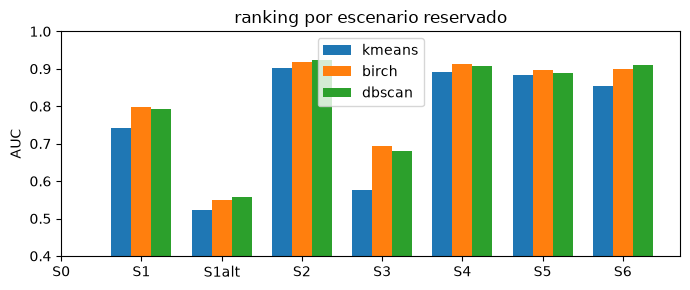

In [16]:
fig, eje = plt.subplots(figsize=(7, 3))
ancho = 0.25
for i, nombre in enumerate(("kmeans", "birch", "dbscan")):
    valores = auc[nombre]
    eje.bar(np.arange(len(valores)) + (i - 1) * ancho, valores, width=ancho, label=nombre)
eje.set_xticks(np.arange(len(auc)))
eje.set_xticklabels(auc.index)
eje.set_ylabel("AUC")
eje.set_ylim(0.4, 1.0)
eje.set_title("ranking por escenario reservado")
eje.legend()
plt.tight_layout()
plt.show()

Lo que dice la tabla:

- **Transferencia a S0:** las tres técnicas marcan entre 15 % y 23 % del tráfico limpio no visto como raro (especificidad 0,77–0,85). Comparado con los supervisados crudos del notebook 02 (especificidad 0,39–0,47), es una diferencia grande.
- **Ranking:** bueno en S2, S4, S5 y S6 (AUC 0,85–0,92), parcial en S1 y malo en S1alt y S3 (0,52–0,69).
- **Calibración:** en S3 ningún modelo marca nada (recall 0) aunque el AUC de BIRCH sea 0,69; en S4 marcan entre 10 % y 53 % de los ataques. La brecha no está en ordenar las filas, está en dónde poner el umbral.

Y el detalle que evita conclusiones de más: con las 15 columnas de la receta física el detector **no mejora**. Lo comprobamos.

In [17]:
base = pd.read_csv("resultados/unsup_loso.csv")
reducido = pd.read_csv("resultados/unsup_loso_reduced.csv")

comparacion = []
for nombre in ("kmeans", "birch", "dbscan"):
    fila = {"modelo": nombre}
    for etiqueta, tabla in (("AUC base", base), ("AUC reducido", reducido)):
        fila[etiqueta] = tabla[tabla["model"] == nombre]["auc"].mean()
    for etiqueta, tabla in (("S0 base", base), ("S0 reducido", reducido)):
        fila[etiqueta] = float(tabla[(tabla["model"] == nombre) & (tabla["fold"] == "S0")]["specificity"].iloc[0])
    comparacion.append(fila)

print(pd.DataFrame(comparacion).round(3).to_string(index=False))

modelo  AUC base  AUC reducido  S0 base  S0 reducido
kmeans     0.767         0.624    0.771        0.680
 birch     0.810         0.681    0.848        0.992
dbscan     0.808         0.684    0.797        0.981


El ranking se cae: la AUC media baja de 0,77–0,81 a 0,62–0,68. La especificidad en S0 es mixta: BIRCH y DBSCAN mejoran a 0,98–0,99, K-Means cae de 0,77 a 0,68.

La razón tiene sentido: al supervisado la reducción le sirve para no aprender el atajo del reloj, pero el no supervisado nunca lo aprendió —entrena solo con benigno, donde el reloj está siempre "normal"—. Sacarle columnas solo le quita resolución para medir distancias.

## 6. El protocolo online y su límite

En producción no hay 1.800 filas benignas etiquetadas para calibrar. Lo único disponible es un tramo inicial que suponemos limpio: el **warm-up**. El protocolo online calibra el umbral en el 20 % inicial del escenario y evalúa sobre el 80 % restante — el escenario completo, incluida la parte benigna que no se usó para calibrar.

In [18]:
online = pd.read_csv("resultados/unsup_online.csv")
resumen_online = online.pivot(index="fold", columns="model", values="specificity").reindex(ESCENARIOS)
print("especificidad por escenario (umbral calibrado con el warm-up)")
print(resumen_online.round(3).to_string())

especificidad por escenario (umbral calibrado con el warm-up)
model  birch  dbscan  kmeans
fold                        
S0     0.106   0.106   0.762
S1     0.956   1.000   0.627
S1alt  1.000   1.000   1.000
S2     0.309   0.309   0.378
S3     1.000   1.000   1.000
S4     1.000   1.000   1.000
S5     0.587   0.587   0.431
S6     0.722   0.722   0.956


In [19]:
print("S0 con umbral de warm-up")
print(online[online["fold"] == "S0"][["model", "specificity", "flagged", "n_test"]].round(3).to_string(index=False))

S0 con umbral de warm-up
 model  specificity  flagged  n_test
kmeans        0.762      342    1438
 birch        0.106     1285    1438
dbscan        0.106     1285    1438


K-Means mantiene 0,762 en S0; BIRCH y DBSCAN caen a **0,106**, o sea marcan el 89 % del tráfico limpio. La causa no es el modelo: el warm-up de S0 tiene puntajes mucho más bajos que el resto del escenario (S0 arranca en un régimen que después se va), así que el umbral queda demasiado bajo y todo lo que viene después parece raro.

**Es un resultado negativo y se reporta como tal.** Un warm-up fijo no representa un régimen benigno que deriva; la calibración por despliegue necesita ser adaptativa (percentil móvil). No se implementó porque el objetivo de esta sección es documentar el límite, no resolverlo.

## 7. En producción

El detector queda guardado como un objeto con todo lo necesario para puntuar una tabla nueva: el preprocesamiento, el modelo, el umbral y la receta de columnas. No hay que volver a entrenar nada.

Ese bundle se ajusta con **todas** las filas benignas juntas, sin reservar ningún escenario: es el modelo que se despliega, no el que se evalúa. Por eso su k y su umbral no coinciden con los del fold S1 de arriba —es otra muestra— y por eso el número que sirve para juzgarlo sigue siendo la tabla de los ocho folds.

In [20]:
bundle = joblib.load("modelos/unsupervised.joblib")
print("claves del bundle:", list(bundle))
print("detrend:", bundle["detrend"], "| ventana:", bundle["window"], "s")
print("umbral guardado:", round(float(bundle["threshold"]), 3))
print("grupos:", bundle["model"].n_clusters)
print("componentes PCA:", bundle["preprocess"].named_steps["pca"].n_components_)

claves del bundle: ['preprocess', 'model', 'detrend', 'window', 'threshold']
detrend: range | ventana: 120 s
umbral guardado: 13.625
grupos: 3
componentes PCA: 16


In [21]:
salida = subprocess.run(
    [sys.executable, "-m", "src.predict", "--model", "unsupervised",
     "--csv", "datasets/datasetS6.csv", "--warmup", "360"],
    capture_output=True, text=True, check=True,
)
print(salida.stdout)

model=unsupervised rows=1,800 threshold=16.4380
flagged=17 (0.9%)
count    1800.0000
mean        8.7024
std         2.4930
min         4.5963
25%         6.7733
50%         8.3925
75%        10.3408
max        21.5904



La línea `flagged` es la que se leería en un tablero: cuántas filas del turno quedaron marcadas y qué porcentaje representan.

Acá hay que mirar el número con desconfianza. El umbral se recalibró con las primeras 360 filas, así que **dentro de ese tramo** marca el 5 % por construcción. Sobre las 1.800 filas de S6 marca el **0,9 %** (17 filas): el umbral quedó alto y casi todo el escenario pasa por normal, aunque buena parte sea ataque. Es la misma inestabilidad de calibración de la sección anterior, vista en un solo escenario.

Para producción eso significa una cosa concreta: el umbral no se fija una vez con un warm-up y se olvida. Se recalibra con percentil móvil, o se opera con el umbral conservador del entrenamiento y se acepta el costo en falsas alarmas.

La versión reducida también está guardada (`modelos/unsupervised_reduced.joblib`) para poder comparar, pero **no se recomienda**: reduce columnas sin mejorar el punto operativo.

## Cierre

Lo que este notebook establece:

1. Un detector entrenado **solo con benigno** transfiere a un escenario limpio no visto bastante mejor que un supervisado crudo: especificidad 0,77–0,85 contra 0,39–0,47.
2. Los grupos que aprende son **regímenes de operación** (día/noche, carga alta/baja), no escenarios: cada grupo mezcla filas de varios archivos.
3. El ranking por escenario es bueno en cuatro de siete escenarios de ataque y malo en tres. **La brecha está en el umbral, no en el orden.**
4. La calibración con warm-up fijo es inestable, porque el régimen benigno deriva dentro del escenario. Es un límite del dataset, no un defecto de implementación.

La conclusión conjunta con el notebook 02: el dataset no soporta "detectar ataques entre escenarios", y sí soporta un detector **dentro de un despliegue** con revisión humana.